# Digital Detective: The Feature Extraction Challenge
Computers do not "see" a cup. They see a grid of pixel numbers. In this lab the computer plays detective: it picks out distinctive clues (**features**) from a photo of a **Second Cup coffee cup**, then tries to find the same clues in a cluttered **table scene**.

We use **ORB** (Oriented FAST and Rotated BRIEF), a fast feature detector built into OpenCV. The notebook follows the worksheet:

| Worksheet | Notebook |
|---|---|
| Mission 1: Training the computer (top 5 features) | Steps 2 and 3 |
| Mission 2: The testing phase (match and evaluate) | Steps 4 and 5 |
| Reflection and discussion (3 questions) | Steps 6 and 7 and the Analysis |

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

# Helper function to display images properly in Jupyter/Colab
def show_img(title, img, figsize=(12, 8)):
    plt.figure(figsize=figsize)
    # Convert BGR (OpenCV default) to RGB (Matplotlib default)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')
    plt.show()

## Step 1: Load and Prepare Images
Upload `Cup.jpeg` (the Second Cup coffee cup, the **target**) and `Table.jpeg` (the cluttered table scene) to your Colab environment or working directory before running this cell. Both images come from the worksheet slides.

Cup image: 1075x1075 px | Scene: 1344x1008 px


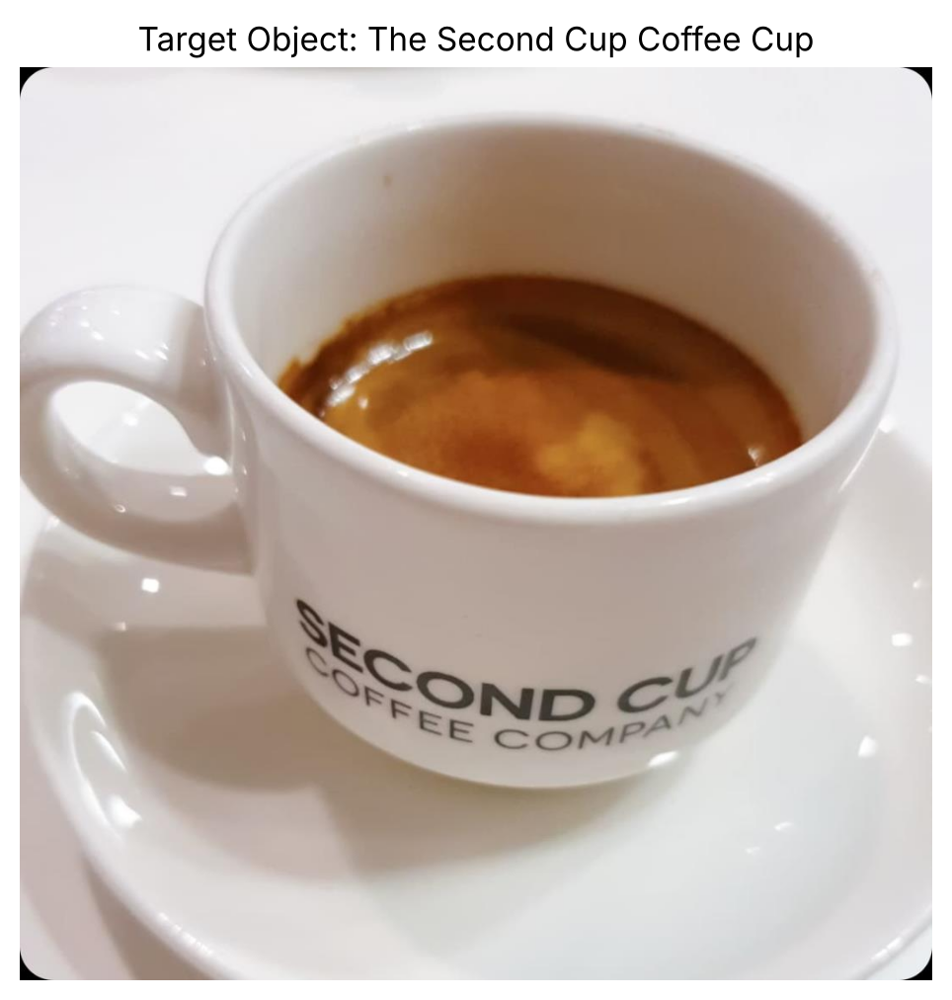

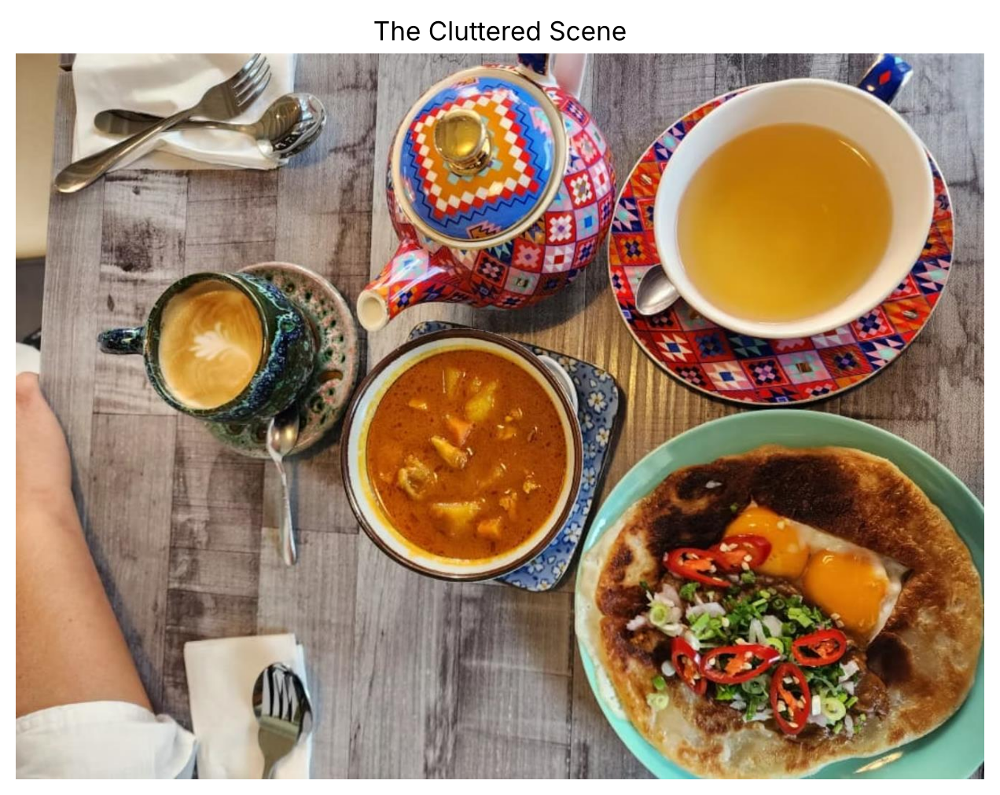

In [2]:
# Load the target image and the scene
img_cup = cv2.imread('Cup.jpeg')
img_table = cv2.imread('Table.jpeg')

if img_cup is None or img_table is None:
    raise FileNotFoundError("Could not load images. Please upload Cup.jpeg and Table.jpeg to the current directory.")

# Convert to grayscale (ORB works on intensity, not colour)
gray_cup = cv2.cvtColor(img_cup, cv2.COLOR_BGR2GRAY)
gray_table = cv2.cvtColor(img_table, cv2.COLOR_BGR2GRAY)
print(f"Cup image: {img_cup.shape[1]}x{img_cup.shape[0]} px | Scene: {img_table.shape[1]}x{img_table.shape[0]} px")

show_img("Target Object: The Second Cup Coffee Cup", img_cup, figsize=(6, 6))
show_img("The Cluttered Scene", img_table, figsize=(8, 6))

## Step 2: Extract Features using ORB (Mission 1)
The computer acts as the detective, finding **keypoints** (corners and blobs where the brightness changes sharply) and describing each one with a 256-bit **descriptor**, a fingerprint of the pixels around it.

Keypoints found: 943 on the cup, 1000 in the scene


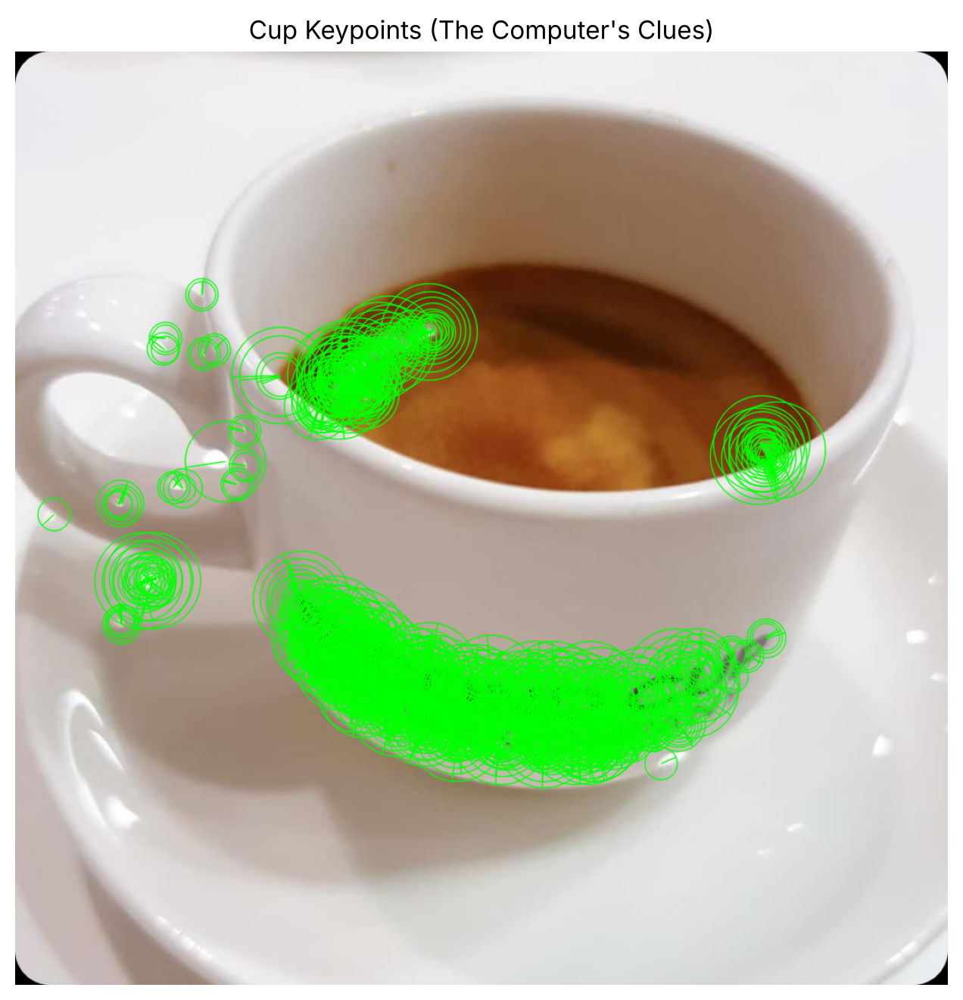

In [3]:
# Initialize the ORB detector (up to 1000 features per image)
orb = cv2.ORB_create(nfeatures=1000)

# Detect keypoints and compute descriptors
kp_cup, des_cup = orb.detectAndCompute(gray_cup, None)
kp_table, des_table = orb.detectAndCompute(gray_table, None)
print(f"Keypoints found: {len(kp_cup)} on the cup, {len(kp_table)} in the scene")

# Visualize every keypoint (circle size = scale, line = orientation)
img_cup_kp = cv2.drawKeypoints(img_cup, kp_cup, None, color=(0, 255, 0),
                               flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
show_img("Cup Keypoints (The Computer's Clues)", img_cup_kp, figsize=(8, 8))

## Step 3: Choose the Top 5 Most Distinctive Features (Mission 1)
The worksheet asks for the **top 5** clues. Instead of taking the first 5 keypoints in the list (which is arbitrary), we rank keypoints by their **response** (corner strength) and keep the strongest ones, skipping any that sit within 150 px of a stronger one so the five clues are spread across the cup rather than bunched together.

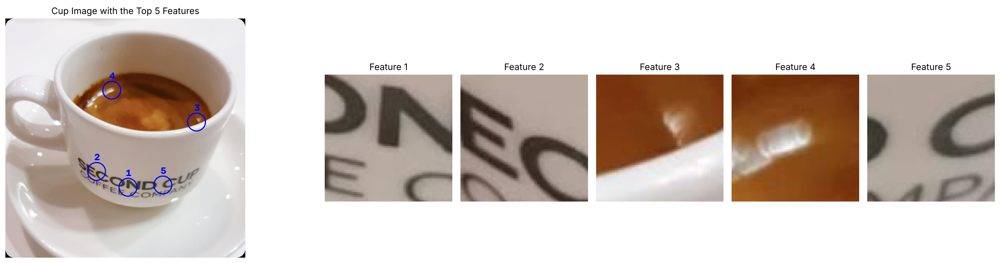

Feature 1: position (549, 758), response 0.00055
Feature 2: position (408, 688), response 0.00045
Feature 3: position (856, 466), response 0.00041
Feature 4: position (477, 322), response 0.00037
Feature 5: position (706, 749), response 0.00027


In [4]:
def top_spread_keypoints(kps, n=5, min_dist=150):
    """Return the indices of the n strongest keypoints that are at least min_dist px apart."""
    chosen = []
    for i in sorted(range(len(kps)), key=lambda i: kps[i].response, reverse=True):
        if all(np.hypot(kps[i].pt[0] - kps[j].pt[0], kps[i].pt[1] - kps[j].pt[1]) >= min_dist for j in chosen):
            chosen.append(i)
        if len(chosen) == n:
            break
    return chosen

top5 = top_spread_keypoints(kp_cup, n=5)

fig, axes = plt.subplots(1, 6, figsize=(20, 5), gridspec_kw={'width_ratios': [3, 1, 1, 1, 1, 1]})
img_cup_annotated = img_cup.copy()
offset = 40  # 40 px in every direction gives an 80x80 patch

for n, idx in enumerate(top5):
    x, y = (int(v) for v in kp_cup[idx].pt)
    cv2.circle(img_cup_annotated, (x, y), offset, (255, 0, 0), 3)
    cv2.putText(img_cup_annotated, str(n + 1), (x - 10, y - offset - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 1.4, (255, 0, 0), 3)
    # Crop the pixel patch (max/min stop it running off the image edge)
    patch = img_cup[max(0, y - offset):min(img_cup.shape[0], y + offset),
                    max(0, x - offset):min(img_cup.shape[1], x + offset)]
    axes[n + 1].imshow(cv2.cvtColor(patch, cv2.COLOR_BGR2RGB))
    axes[n + 1].set_title(f"Feature {n + 1}")
    axes[n + 1].axis('off')

axes[0].imshow(cv2.cvtColor(img_cup_annotated, cv2.COLOR_BGR2RGB))
axes[0].set_title("Cup Image with the Top 5 Features")
axes[0].axis('off')
plt.tight_layout()
plt.show()

for n, idx in enumerate(top5):
    print(f"Feature {n + 1}: position ({kp_cup[idx].pt[0]:.0f}, {kp_cup[idx].pt[1]:.0f}), response {kp_cup[idx].response:.5f}")

## Step 4: Match the Features to the Scene (Mission 2)
Now the computer searches the scene for each clue. A **Brute-Force matcher** compares descriptors using Hamming distance (the number of differing bits). A lower distance means a more similar clue.

First we draw a line from each of the **5 chosen features** to its best match in the scene, exactly like the line-drawing step in the worksheet.

Feature 1 -> scene point (1048, 442), Hamming distance 66 / 256
Feature 2 -> scene point (924, 112), Hamming distance 50 / 256
Feature 3 -> scene point (961, 761), Hamming distance 53 / 256
Feature 4 -> scene point (1157, 878), Hamming distance 67 / 256
Feature 5 -> scene point (923, 785), Hamming distance 69 / 256


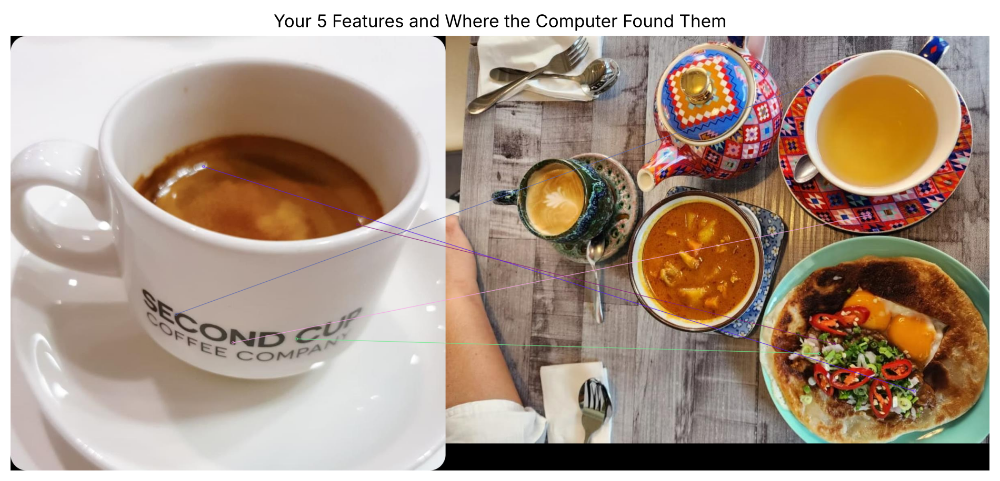

In [5]:
bf_knn = cv2.BFMatcher(cv2.NORM_HAMMING)

# Best scene match for each of the 5 chosen cup features
five_matches = []
for idx in top5:
    best = bf_knn.knnMatch(des_cup[idx:idx + 1], des_table, k=1)[0][0]
    best.queryIdx = idx
    five_matches.append(best)

for n, m in enumerate(five_matches):
    x, y = kp_table[m.trainIdx].pt
    print(f"Feature {n + 1} -> scene point ({x:.0f}, {y:.0f}), Hamming distance {m.distance:.0f} / 256")

img_five = cv2.drawMatches(img_cup, kp_cup, img_table, kp_table, five_matches, None,
                           flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
show_img("Your 5 Features and Where the Computer Found Them", img_five)

Total features matched: 211


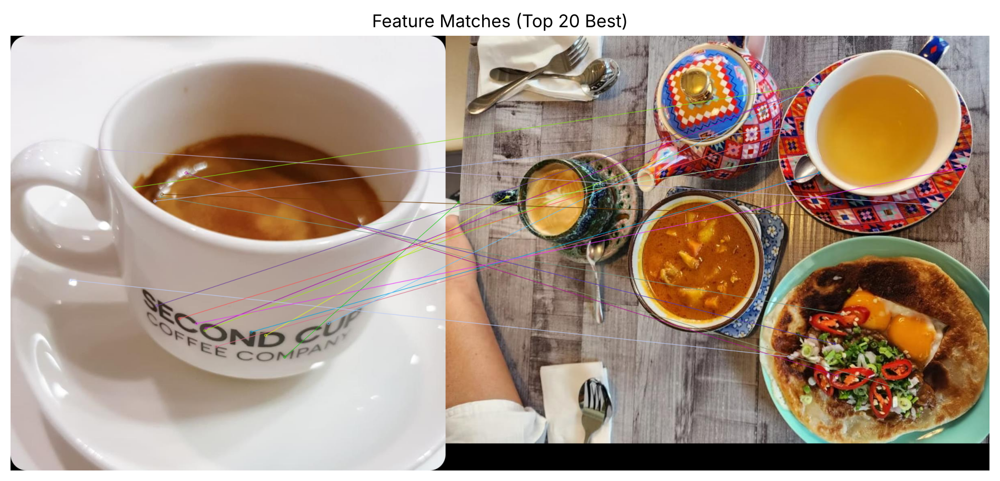

In [6]:
# Match ALL cup descriptors to the scene (cross-check keeps only mutual best pairs)
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = sorted(bf.match(des_cup, des_table), key=lambda x: x.distance)
print(f"Total features matched: {len(matches)}")

img_matches = cv2.drawMatches(img_cup, kp_cup, img_table, kp_table, matches[:20], None,
                              flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
show_img("Feature Matches (Top 20 Best)", img_matches)

## Step 5: Where Did the Matches Land? (Mission 2, Evaluate Reliability)
Looking at the lines by eye is not enough, so we count them. The scene has no second Second Cup mug, so the best answer is the **white teacup in the top right**, the closest look-alike. The other objects are rough circles placed by eye. A match is **correct** if it lands on the teacup and a **false match** if it lands anywhere else.

We also add **Lowe's ratio test**: keep a match only if it is clearly better than the second-best candidate (distance below 0.75 times the second-best distance).

Top-20 cross-check matches : 6 of 20 on the white teacup | table/other: 7, white teacup: 6, roti plate: 5, teapot: 2
All cross-check matches    : 42 of 211 on the white teacup | table/other: 69, roti plate: 58, white teacup: 42, teapot: 32, latte cup: 8, cutlery/napkin: 2
Ratio-test matches         : 5 of 14 on the white teacup | white teacup: 5, roti plate: 5, teapot: 2, table/other: 2
The 5 chosen features      : 1 of 5 on the white teacup | roti plate: 3, table/other: 1, white teacup: 1


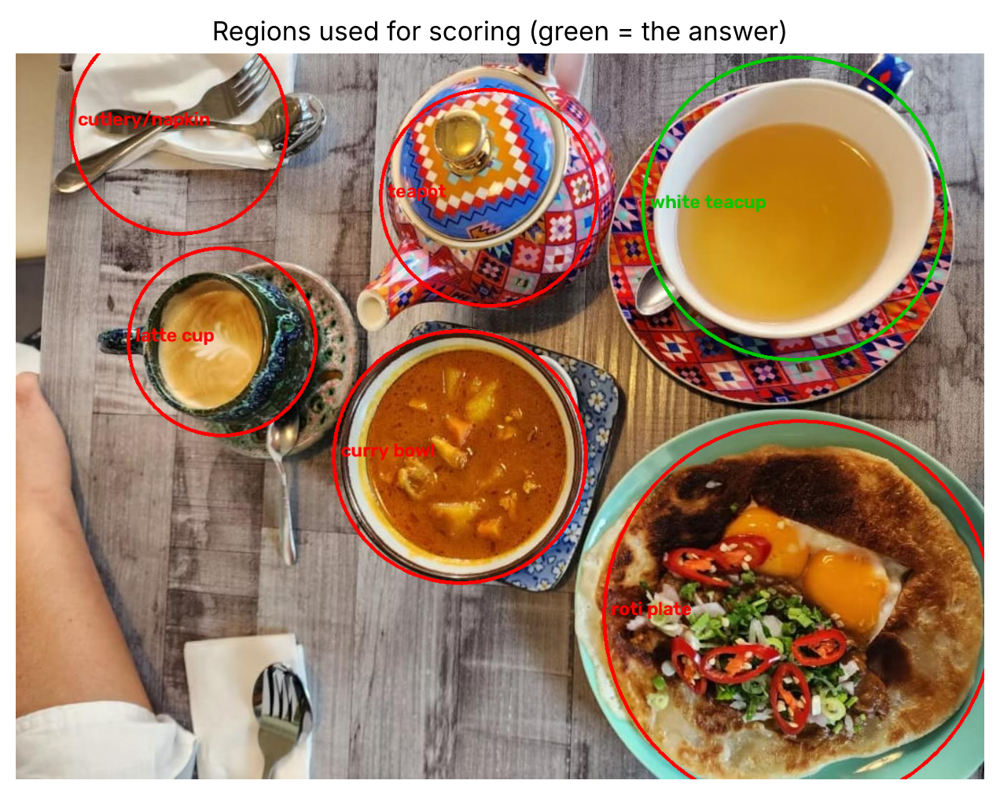

In [7]:
# Approximate object locations in Table.jpeg: (centre x, centre y, radius), measured by eye
REGIONS = {
    'white teacup':   (1080, 215, 210),
    'teapot':         (656, 200, 150),
    'latte cup':      (286, 400, 130),
    'curry bowl':     (616, 560, 175),
    'roti plate':     (1086, 780, 270),
    'cutlery/napkin': (226, 100, 150),
}

def region_of(pt):
    for name, (cx, cy, r) in REGIONS.items():
        if (pt[0] - cx) ** 2 + (pt[1] - cy) ** 2 < r ** 2:
            return name
    return 'table/other'

def report(label, ms):
    c = Counter(region_of(kp_table[m.trainIdx].pt) for m in ms)
    on = c['white teacup']
    print(f"{label}: {on} of {len(ms)} on the white teacup | " + ", ".join(f"{k}: {v}" for k, v in c.most_common()))

report("Top-20 cross-check matches ", matches[:20])
report("All cross-check matches    ", matches)

knn = bf_knn.knnMatch(des_cup, des_table, k=2)
good = [a for a, b in knn if a.distance < 0.75 * b.distance]
report("Ratio-test matches         ", good)
report("The 5 chosen features      ", five_matches)

# Show the regions so the counts can be checked by eye
img_regions = img_table.copy()
for name, (cx, cy, r) in REGIONS.items():
    colour = (0, 200, 0) if name == 'white teacup' else (0, 0, 255)
    cv2.circle(img_regions, (cx, cy), r, colour, 3)
    cv2.putText(img_regions, name, (cx - r + 10, cy), cv2.FONT_HERSHEY_SIMPLEX, 0.9, colour, 2)
show_img("Regions used for scoring (green = the answer)", img_regions, figsize=(8, 6))

## Step 6: Robustness Challenge (Reflection Question 3)
Would the features still work if the cup were **rotated** or the **lighting** were different? We transform the cup photo, re-extract features, and count the ratio-test matches that land on the white teacup.

In [8]:
def test_variant(label, img):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    kp, des = orb.detectAndCompute(g, None)
    pairs = bf_knn.knnMatch(des, des_table, k=2)
    ok = [a for a, b in pairs if a.distance < 0.75 * b.distance]
    on = sum(region_of(kp_table[m.trainIdx].pt) == 'white teacup' for m in ok)
    print(f"{label:<26} keypoints: {len(kp):4d} | ratio-test matches: {len(ok):3d} | on the teacup: {on}")
    return ok, kp

def rotate(img, angle):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    return cv2.warpAffine(img, M, (w, h), borderValue=(255, 255, 255))

test_variant("Original", img_cup)
test_variant("Rotated 45 degrees", rotate(img_cup, 45))
test_variant("Rotated 90 degrees", rotate(img_cup, 90))
test_variant("Darker (50% brightness)", cv2.convertScaleAbs(img_cup, alpha=0.5, beta=0))
test_variant("Brighter (+60)", cv2.convertScaleAbs(img_cup, alpha=1.0, beta=60))
test_variant("Half size", cv2.resize(img_cup, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA))
test_variant("Quarter size", cv2.resize(img_cup, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA))

Original                   keypoints:  943 | ratio-test matches:  14 | on the teacup: 5
Rotated 45 degrees         keypoints:  899 | ratio-test matches:  14 | on the teacup: 6
Rotated 90 degrees         keypoints:  937 | ratio-test matches:   9 | on the teacup: 4
Darker (50% brightness)    keypoints:  557 | ratio-test matches:   5 | on the teacup: 1
Brighter (+60)             keypoints:  889 | ratio-test matches:   9 | on the teacup: 4
Half size                  keypoints:  958 | ratio-test matches:  12 | on the teacup: 6
Quarter size               keypoints:  455 | ratio-test matches:   4 | on the teacup: 3


([< cv2.DMatch 0x7f7790052310>,
  < cv2.DMatch 0x7f7790052cb0>,
  < cv2.DMatch 0x7f7790074230>,
  < cv2.DMatch 0x7f7790074670>],
 (< cv2.KeyPoint 0x7f779019acd0>,
  < cv2.KeyPoint 0x7f77901993e0>,
  < cv2.KeyPoint 0x7f7790198510>,
  < cv2.KeyPoint 0x7f779019b9f0>,
  < cv2.KeyPoint 0x7f779019ab80>,
  < cv2.KeyPoint 0x7f77901ba790>,
  < cv2.KeyPoint 0x7f77901babb0>,
  < cv2.KeyPoint 0x7f77901ba7c0>,
  < cv2.KeyPoint 0x7f77901b8270>,
  < cv2.KeyPoint 0x7f77901b8870>,
  < cv2.KeyPoint 0x7f77901b9c80>,
  < cv2.KeyPoint 0x7f77901b9c50>,
  < cv2.KeyPoint 0x7f77901badf0>,
  < cv2.KeyPoint 0x7f77901bb870>,
  < cv2.KeyPoint 0x7f77901ba400>,
  < cv2.KeyPoint 0x7f77901b8030>,
  < cv2.KeyPoint 0x7f77901b8de0>,
  < cv2.KeyPoint 0x7f77901b80c0>,
  < cv2.KeyPoint 0x7f77901baca0>,
  < cv2.KeyPoint 0x7f77901b90e0>,
  < cv2.KeyPoint 0x7f77901bb360>,
  < cv2.KeyPoint 0x7f77901bae80>,
  < cv2.KeyPoint 0x7f77901bb3f0>,
  < cv2.KeyPoint 0x7f77901ba490>,
  < cv2.KeyPoint 0x7f77901bb5a0>,
  < cv2.KeyPoint 0x7f

## Analysis: What the Detective Found

**Result.** ORB found 943 keypoints on the cup and 1,000 in the scene, and the cross-check matcher returned **211 matches**. Only **6 of the top 20** landed on the white teacup (the closest look-alike); the rest landed on the roti plate (5), the teapot (2) and plain table or other areas (7). The teacup covers only about 10% of the scene, so 30% is better than random guessing, but it is nowhere near reliable. The ratio test cut the 211 matches to 14, and 5 of those 14 were on the teacup. The 5 hand-picked features did worse: only **1 of 5** (Feature 2, an edge of a logo letter) matched the teacup rim, while Features 3 and 4 (bright highlights on the coffee) and Features 1 and 5 (logo letters) matched the roti plate.

**Reflection 1: Which feature was most useful, and why?** Feature 2 was the only one of the five that matched the right object. It is a sharp, high-contrast curved edge where dark ink meets white ceramic, and a white cup rim in the scene produces a similar edge. The coffee highlights (Features 3 and 4) were strong corners, but a glint is a property of the lighting, not of the cup, so it also matches glossy things like the fried egg and roti.

**Reflection 2: Ambiguous or false matches.** Most matches were false. The roti plate attracted the most (58 of all 211 matches) because its dark charred patches, bright egg yolks and sharp chilli edges contain many strong, varied corners. The teapot (32 of 211) has a dense repeating geometric pattern, which gives lots of corners that look alike. A feature is only useful if it is both **distinctive** (unique to the cup) and **repeatable** (found again in the scene), and most of ours were neither.

**Reflection 3: Robustness.** Rotation was not a problem: at 45 degrees ORB kept 14 ratio-test matches (6 on the teacup) and at 90 degrees it kept 9 (4 on the teacup), because ORB measures each keypoint's orientation and rotates its descriptor to match. Lighting and size mattered more. At half brightness the keypoints dropped from 943 to 557 and only 1 match landed on the teacup, because FAST corner detection depends on brightness differences. Shrinking the cup to a quarter of its size left only 455 keypoints and 4 matches. These counts are small, so treat the differences as hints rather than proof.

**Why it was hard.**
1. **Different object.** The scene contains no Second Cup mug, so the logo, the strongest clue, has nothing to match. The teacup is only a look-alike, with no text.
2. **Different viewpoint.** The cup photo is a close-up from the side, while the scene is a top-down photo. The cup appears from a different angle, at a different size, and mixed in with a lot of other objects.
3. **Low texture.** White ceramic has few corners apart from the logo and the rim, while the busy scene has hundreds of strong corners elsewhere.
4. **Cross-check always returns something.** The number 211 says nothing about quality, which is why the ratio test, with only 14 survivors, is more informative.

**Takeaway.** Feature matching works best when the target is textured, rigid and seen from a similar angle and scale. Plain white cups in a cluttered scene need stronger methods, such as SIFT with RANSAC geometric verification (which rejects matches that do not agree on one position), or a trained object detector.